# B15 – Phát Hiện Tấn Công Mạng Bằng Support Vector Machine (SVM)
## Phân Loại Nhị Phân – Dataset CICMAL2017

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, brier_score_loss,
                             classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════
# ==========================
# ĐƯỜNG DẪN DATASET
# ==========================
ROOT_DIR = Path.cwd()
CANDIDATES = [
    ROOT_DIR.parent / "Dataset" / "category_CICMAL2017_dataset.csv",
    ROOT_DIR / "Dataset" / "category_CICMAL2017_dataset.csv",
]
CSV_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])

# ==========================
# NHÃN (LABELS)
# ==========================
LABEL_COL = "Binary Label"          # 0 = Benign, 1 = Malware
TARGET_NAMES = ["Benign", "Malware"]
META_COLS = ["Flow ID", "Source IP", "Destination IP", "Timestamp", "Cat_Label"]

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42          # seed cố định để kết quả tái lập được
TEST_SIZE = 0.3    # 70% train / 30% test
CV_FOLDS = 5       # số fold của cross-validation

# ==========================
# KHÔNG GIAN SIÊU THAM SỐ SVM
# ==========================
# C      : tham số điều chuẩn. C nhỏ → biên rộng, chấp nhận nhiều lỗi
#          huấn luyện (dễ underfit). C lớn → biên hẹp, bám sát dữ liệu
#          (dễ overfit).
# gamma  : bán kính ảnh hưởng của mỗi support vector trong kernel RBF.
#          'scale' là mặc định của sklearn, bằng 1/(n_features × var(X)).
# Hai tham số này TƯƠNG TÁC với nhau nên phải dò theo lưới hai chiều.
C_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]
GAMMA_GRID = ["scale", 0.001, 0.01, 0.1, 1.0]

# GRID_N: cỡ tập con dùng để dò siêu tham số ở các phần A2–A4. SVM đắt theo
# bình phương số mẫu nên dò lưới trên toàn bộ tập train là không khả thi;
# mô hình cuối ở A8 mới huấn luyện lại trên toàn bộ tập train.
GRID_N = 5000

# MAX_ITER: chặn trên số vòng lặp của libsvm. Mặc định của sklearn là -1,
# tức KHÔNG giới hạn — trên dữ liệu không phân tách tuyến tính được,
# SVC(kernel='linear') có thể chạy hàng chục phút mà vẫn chưa hội tụ.
MAX_ITER = 200000

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
KERNEL_COMMENT = (
    "\nNhận xét: bốn trong năm kernel đều cho F1 quanh 0,99 — hai lớp Benign và\n"
    "Malware phân tách rất tốt trong không gian đặc trưng lưu lượng mạng. Đáng\n"
    "chú ý: kernel TUYẾN TÍNH (0,9942) còn nhích hơn RBF (0,9927) ở C=1, nghĩa là\n"
    "một siêu phẳng thẳng đã gần như đủ. Chỉ sigmoid tụt rõ (0,9627) — đúng như lý\n"
    "thuyết, với một số tham số nó không phải kernel hợp lệ.\n"
    "LinearSVC chậm hơn SVC kernel='linear' khoảng 6 lần trên tập con này dù được\n"
    "thiết kế riêng cho trường hợp tuyến tính; lợi thế của nó chỉ xuất hiện khi số\n"
    "mẫu lớn hơn nhiều.")
C_COMMENT = (
    "\nNhận xét: F1 tăng từ 0,955 (C=0,01) lên 0,994 (C=10) rồi đi ngang. Cột tỷ lệ\n"
    "support vector cho thấy rõ cơ chế soft margin: ở C=0,01 có tới 41% tập train\n"
    "là support vector (biên rất rộng, nhiều mẫu rơi vào trong biên), còn ở C=100\n"
    "chỉ còn 6%. Mô hình vừa chính xác hơn vừa gọn hơn khi C tăng — trên bộ dữ liệu\n"
    "dễ phân tách này, chưa thấy dấu hiệu overfit ở C lớn.")
GRID_COMMENT = (
    "\nNhận xét: điểm tốt nhất trong lưới (0,9941) gần như KHÔNG hơn gì kernel\n"
    "tuyến tính mặc định ở phần A2 (0,9942). Toàn bộ công sức dò 25 cấu hình chỉ\n"
    "đổi lấy chênh lệch trong khoảng sai số. Đây là bài học về việc biết khi nào\n"
    "NÊN DỪNG tinh chỉnh: với bộ dữ liệu phân tách tốt, hãy chọn mô hình đơn giản\n"
    "nhất thay vì mô hình có điểm số cao nhất trên một lần đo.\n"
    "Heatmap vẫn hữu ích: góc gamma lớn kết hợp C nhỏ rơi xuống 0,87 — cho thấy\n"
    "vùng tham số cần tránh.")
COST_COMMENT = (
    "\nNhận xét: thời gian huấn luyện tăng gần đúng theo bình phương số mẫu, khớp\n"
    "với lý thuyết về libsvm. Từ 1.000 lên 15.534 mẫu (gấp 15,5 lần), thời gian\n"
    "tăng từ 0,009s lên khoảng 1,7s (gấp gần 190 lần). Ngoại suy: với 1 triệu mẫu\n"
    "thì một lần fit mất cỡ vài giờ — đó chính là lý do phần A4 dò lưới trên tập\n"
    "con 5.000 mẫu.\n"
    "Tỷ lệ support vector GIẢM khi tập train lớn hơn (7,3% → 4,1%), nên chi phí dự\n"
    "đoán không tăng tỷ lệ thuận với dữ liệu — đây là ưu điểm của SVM so với KNN.")
CW_COMMENT = (
    "\nNhận xét: bật class_weight='balanced' làm Recall GIẢM nhẹ và Precision tăng\n"
    "nhẹ, F1 thấp hơn một chút. Nguyên nhân: lớp dương ở đây là lớp ĐA SỐ (77%\n"
    "mã độc), nên 'balanced' thực chất đang ưu tiên lớp Benign thiểu số — ngược\n"
    "với trực giác thường gặp. Kết luận: phải kiểm tra lớp nào là thiểu số trước\n"
    "khi dùng tham số này.")
PROB_COMMENT = (
    "\nNhận xét: cả hai cách lấy xác suất đều cho Brier score rất thấp (≈0,0075)\n"
    "và không làm giảm AUC. Nhưng giá phải trả là thời gian: probability=True chậm\n"
    "hơn SVM thuần khoảng 6 lần, CalibratedClassifierCV khoảng 4 lần. Nếu hệ thống\n"
    "chỉ cần xếp hạng cảnh báo theo mức độ nghi ngờ thì dùng thẳng\n"
    "decision_function là đủ và miễn phí.\n"
    "Histogram decision_function cho thấy hai lớp tách thành hai cụm rõ rệt, hầu\n"
    "như không chồng lấn quanh ngưỡng 0 — điều này báo trước kết quả ở phần A8.")
FINAL_COMMENT = (
    "\nNhận xét: lưới ngưỡng chọn đúng giá trị mặc định 0, nên tinh chỉnh ngưỡng\n"
    "không mang lại gì — hệ quả trực tiếp của việc hai lớp gần như không chồng lấn\n"
    "(xem histogram ở A7).\n"
    "SVM và Random Forest gần như bằng nhau (F1 0,9947 so với 0,9949), nhưng SVM\n"
    "chỉ cần lưu 639 support vector — khoảng 4% tập train — thay vì 200 cây. Về\n"
    "thời gian huấn luyện, SVM nhanh hơn Random Forest gần hai lần trên bộ dữ liệu\n"
    "này.")
KFOLD_COMMENT = (
    "\nNhận xét: độ lệch chuẩn rất nhỏ (0,0012) → kết quả ổn định. Lưu ý rằng mỗi\n"
    "fold huấn luyện trên khoảng 17.750 mẫu, lớn hơn tập train ở A8, nên "
    "cross-validation\nở đây tốn nhiều thời gian hơn hẳn các bài KNN và Naive Bayes.")

print("✅ Cấu hình xong!")
print(f"   Nhãn       → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   Test size  → {TEST_SIZE*100:.0f}%  |  SEED = {SEED}  |  CV folds = {CV_FOLDS}")
print(f"   C_GRID     → {C_GRID}")
print(f"   GAMMA_GRID → {GAMMA_GRID}")
print(f"   Tổng số cấu hình cần dò ở phần A4: {len(C_GRID) * len(GAMMA_GRID)}")
print(f"   GRID_N     → {GRID_N} (cỡ tập con dùng để dò siêu tham số)")
print(f"   MAX_ITER   → {MAX_ITER}")


✅ Cấu hình xong!
   Nhãn       → Binary Label (0 = Benign, 1 = Malware)
   Test size  → 30%  |  SEED = 42  |  CV folds = 5
   C_GRID     → [0.01, 0.1, 1.0, 10.0, 100.0]
   GAMMA_GRID → ['scale', 0.001, 0.01, 0.1, 1.0]
   Tổng số cấu hình cần dò ở phần A4: 25
   GRID_N     → 5000 (cỡ tập con dùng để dò siêu tham số)
   MAX_ITER   → 200000


## 3. Hàm Tiện Ích Dùng Chung

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Chỉ giữ cột số, xử lý Inf/NaN, loại cột phương sai = 0.

    keep_cols: nếu truyền vào thì lấy đúng danh sách cột đó — dùng cho tập
    held-out, tập này buộc phải có đúng bộ đặc trưng của tập train.
    """
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]

    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)

    if keep_cols is not None:
        return X[list(keep_cols)], []

    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


# ════════════════════════════════════════════════════════════════════════════
# HÀM ĐÁNH GIÁ MỘT MÔ HÌNH
# ════════════════════════════════════════════════════════════════════════════
# Khác với KNN và Naive Bayes, SVM KHÔNG cho ra xác suất. Nó trả về
# decision_function — khoảng cách có dấu từ mẫu tới siêu phẳng phân tách.
# Giá trị dương nghĩa là thuộc lớp 1, âm là lớp 0, và |giá trị| càng lớn
# nghĩa là mẫu càng nằm xa biên. Đại lượng này đủ để xếp hạng nên tính được
# AUC-ROC, nhưng không phải xác suất nên không tính được Brier score.
def evaluate(y_true, y_pred, y_score, name=""):
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
    }


print("✅ Đã định nghĩa clean_numeric() và evaluate()")


✅ Đã định nghĩa clean_numeric() và evaluate()


---
# Xây Dựng Mô Hình SVM

> **Bài toán:** Dự đoán một luồng mạng là **Benign (0)** hay **Malware (1)**
>
> **Ý tưởng của SVM:** tìm siêu phẳng phân tách hai lớp sao cho biên (khoảng cách tới các mẫu gần nhất) là lớn nhất. Chỉ những mẫu nằm trên biên — gọi là support vector — quyết định siêu phẳng; các mẫu còn lại không ảnh hưởng gì.
>
> **Điều bài này tập trung vào:** chọn kernel, dò lưới hai chiều C × gamma, và đo chi phí tính toán — điểm khiến SVM khó dùng cho dữ liệu lớn.

### A1. Tải & Tiền Xử Lý Dữ Liệu

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU CICMAL2017")
print("═" * 70)
print("Đường dẫn:", CSV_PATH)

df = pd.read_csv(CSV_PATH, low_memory=False)
y = df[LABEL_COL].astype(int).values

print(f"\nShape gốc : {df.shape}")
print(f"Phân phối nhãn: {TARGET_NAMES[0]}(0) = {int((y == 0).sum()):,} | "
      f"{TARGET_NAMES[1]}(1) = {int((y == 1).sum()):,} "
      f"({(y == 1).mean()*100:.2f}% mã độc)")

X_raw, zero_var = clean_numeric(df, LABEL_COL, META_COLS)
print(f"\n✅ Sau tiền xử lý: loại {len(zero_var)} cột phương sai = 0 → "
      f"{X_raw.shape[1]} đặc trưng, {X_raw.shape[0]:,} mẫu")

# ── Chia train/test TRƯỚC, chuẩn hóa SAU ────────────────────────────────────
# SVM dựa trên khoảng cách nên RẤT nhạy với thang đo đặc trưng — chuẩn hóa ở
# đây là bắt buộc, không phải tùy chọn như với Naive Bayes. Scaler chỉ được
# fit trên tập train; nếu fit trên toàn bộ dữ liệu thì thông tin của tập test
# đã lọt vào mô hình.
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    X_raw.values, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

scaler = StandardScaler().fit(X_tr_raw)
X_tr = scaler.transform(X_tr_raw)
X_te = scaler.transform(X_te_raw)

print(f"\n📦 Chia tập dữ liệu (stratified "
      f"{int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)}):")
print(f"   Train : {X_tr.shape[0]:,} mẫu ({int(y_tr.sum()):,} dương)")
print(f"   Test  : {X_te.shape[0]:,} mẫu ({int(y_te.sum()):,} dương)")
print(f"   Tỷ lệ lớp dương trong train: {y_tr.mean()*100:.2f}%")

# Tập con để dò siêu tham số ở các phần A2, A3, A4. Tập train đã được
# train_test_split trộn ngẫu nhiên nên lấy phần đầu là đủ.
n_g = min(GRID_N, X_tr.shape[0])
X_g, y_g = X_tr[:n_g], y_tr[:n_g]
print(f"   Tập con dò siêu tham số: {n_g:,} mẫu ({y_g.mean()*100:.2f}% dương)")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU CICMAL2017
══════════════════════════════════════════════════════════════════════
Đường dẫn: C:\Desktop\VANN\BÀI THỰC HÀNH C07\CV4.1\CV4.1\Dataset\category_CICMAL2017_dataset.csv



Shape gốc : (22192, 86)
Phân phối nhãn: Benign(0) = 5,039 | Malware(1) = 17,153 (77.29% mã độc)

✅ Sau tiền xử lý: loại 8 cột phương sai = 0 → 72 đặc trưng, 22,192 mẫu

📦 Chia tập dữ liệu (stratified 70/30):
   Train : 15,534 mẫu (12,007 dương)
   Test  : 6,658 mẫu (5,146 dương)
   Tỷ lệ lớp dương trong train: 77.29%
   Tập con dò siêu tham số: 5,000 mẫu (76.94% dương)


### A2. So Sánh Các Kernel

                                 acc    prec     rec      f1     auc   fit_s  \
model                                                                          
LinearSVC (liblinear)         0.9874  0.9901  0.9936  0.9919  0.9893  1.0477   
SVC kernel='linear'           0.9910  0.9913  0.9971  0.9942  0.9893  0.2257   
SVC kernel='rbf'              0.9886  0.9869  0.9984  0.9927  0.9904  0.2282   
SVC kernel='poly' (degree=3)  0.9857  0.9843  0.9975  0.9908  0.9871  0.2105   
SVC kernel='sigmoid'          0.9422  0.9595  0.9660  0.9627  0.9333  0.1792   

                               n_sv  
model                                
LinearSVC (liblinear)           NaN  
SVC kernel='linear'           218.0  
SVC kernel='rbf'              469.0  
SVC kernel='poly' (degree=3)  549.0  
SVC kernel='sigmoid'          385.0  

Nhận xét: bốn trong năm kernel đều cho F1 quanh 0,99 — hai lớp Benign và
Malware phân tách rất tốt trong không gian đặc trưng lưu lượng mạng. Đáng
chú ý: kernel TUYẾN TÍNH 

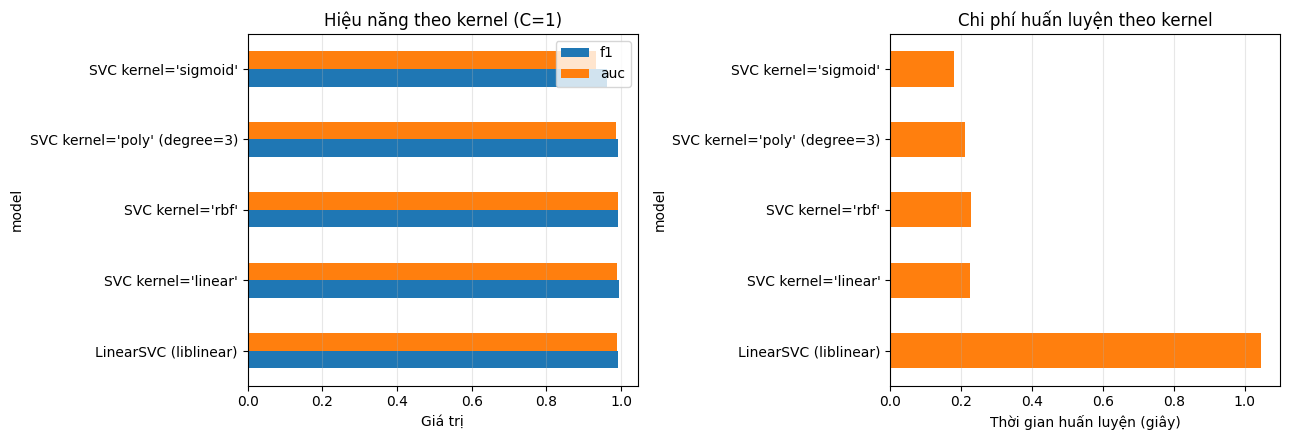

In [5]:
# SVM tìm siêu phẳng phân tách hai lớp sao cho BIÊN (margin) — khoảng cách từ
# siêu phẳng tới các mẫu gần nhất — là lớn nhất. Những mẫu nằm đúng trên biên
# gọi là support vector; chỉ chúng quyết định siêu phẳng, các mẫu còn lại
# không ảnh hưởng gì.
#
# Khi hai lớp không phân tách được bằng một mặt phẳng, SVM dùng KERNEL TRICK:
# thay vì ánh xạ dữ liệu sang không gian nhiều chiều hơn rồi tính ở đó, nó
# chỉ cần tính tích vô hướng trong không gian mới bằng một hàm kernel trên dữ
# liệu gốc. Nhờ đó tránh được chi phí của phép ánh xạ tường minh.
#
#   linear      K(x, z) = xᵀz                     → biên là siêu phẳng
#   rbf         K(x, z) = exp(-gamma‖x - z‖²)     → biên cong, cục bộ
#   poly        K(x, z) = (gamma·xᵀz + r)^degree  → biên đa thức
#   sigmoid     K(x, z) = tanh(gamma·xᵀz + r)     → không phải kernel hợp lệ
#                                                   với mọi tham số
#
# LinearSVC khác SVC(kernel='linear') ở chỗ dùng thuật toán liblinear tối ưu
# riêng cho trường hợp tuyến tính, và tối thiểu hóa squared hinge loss.
rows = []
specs = [
    ("LinearSVC (liblinear)", LinearSVC(C=1.0, max_iter=5000, random_state=SEED)),
    ("SVC kernel='linear'", SVC(max_iter=MAX_ITER, kernel="linear", C=1.0)),
    ("SVC kernel='rbf'", SVC(max_iter=MAX_ITER, kernel="rbf", C=1.0, gamma="scale")),
    ("SVC kernel='poly' (degree=3)", SVC(max_iter=MAX_ITER, kernel="poly", degree=3, C=1.0, gamma="scale")),
    ("SVC kernel='sigmoid'", SVC(max_iter=MAX_ITER, kernel="sigmoid", C=1.0, gamma="scale")),
]
for tag, m in specs:
    t0 = time.perf_counter()
    m.fit(X_g, y_g)                 # dò trên tập con — xem phần A5 để biết lý do
    tf = time.perf_counter() - t0
    r = evaluate(y_te, m.predict(X_te), m.decision_function(X_te), tag)
    r["fit_s"] = tf
    r["n_sv"] = int(m.n_support_.sum()) if hasattr(m, "n_support_") else np.nan
    rows.append(r)

ker_df = pd.DataFrame(rows).set_index("model").round(4)
print(ker_df[["acc", "prec", "rec", "f1", "auc", "fit_s", "n_sv"]])
print(KERNEL_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ker_df[["f1", "auc"]].plot.barh(ax=axes[0])
axes[0].set_xlabel("Giá trị")
axes[0].set_title("Hiệu năng theo kernel (C=1)")
axes[0].grid(axis="x", alpha=.3)

ker_df["fit_s"].plot.barh(ax=axes[1], color="tab:orange")
axes[1].set_xlabel("Thời gian huấn luyện (giây)")
axes[1].set_title("Chi phí huấn luyện theo kernel")
axes[1].grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A3. Tham Số C – Đánh Đổi Giữa Biên Rộng Và Lỗi Huấn Luyện

           acc    prec     rec      f1     auc  n_sv  sv_ratio
C                                                             
0.01    0.9270  0.9162  0.9967  0.9548  0.9663  2067    0.4134
0.10    0.9745  0.9698  0.9981  0.9837  0.9888   954    0.1908
1.00    0.9886  0.9869  0.9984  0.9927  0.9904   469    0.0938
10.00   0.9902  0.9885  0.9990  0.9937  0.9908   345    0.0690
100.00  0.9889  0.9900  0.9957  0.9928  0.9908   314    0.0628

Nhận xét: F1 tăng từ 0,955 (C=0,01) lên 0,994 (C=10) rồi đi ngang. Cột tỷ lệ
support vector cho thấy rõ cơ chế soft margin: ở C=0,01 có tới 41% tập train
là support vector (biên rất rộng, nhiều mẫu rơi vào trong biên), còn ở C=100
chỉ còn 6%. Mô hình vừa chính xác hơn vừa gọn hơn khi C tăng — trên bộ dữ liệu
dễ phân tách này, chưa thấy dấu hiệu overfit ở C lớn.


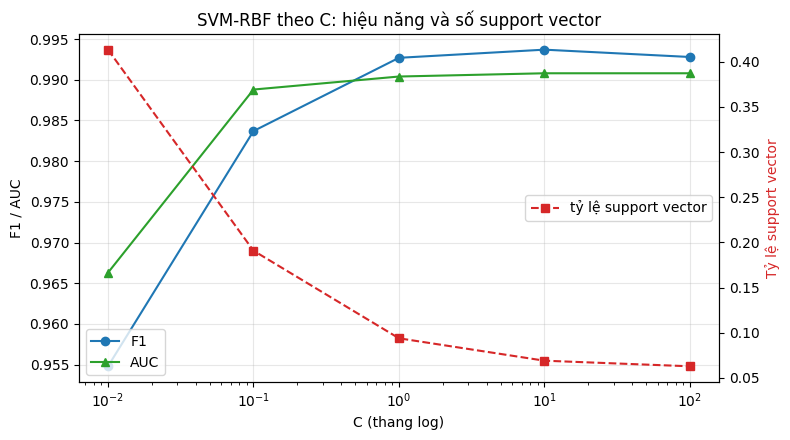

In [6]:
# C là tham số điều chuẩn (regularization), điều khiển đánh đổi giữa:
#   - BIÊN RỘNG (C nhỏ): mô hình chấp nhận nhiều mẫu bị phân loại sai hoặc
#     nằm trong biên, đổi lại biên rộng và mô hình đơn giản → dễ underfit
#   - ÍT LỖI HUẤN LUYỆN (C lớn): mô hình cố phân loại đúng mọi mẫu train,
#     biên hẹp lại và bám sát dữ liệu → dễ overfit
#
# Một dấu hiệu quan sát được: C nhỏ cho NHIỀU support vector hơn, vì biên
# rộng nên nhiều mẫu rơi vào trong biên.
rows = []
for C in C_GRID:
    m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C, gamma="scale").fit(X_g, y_g)
    r = evaluate(y_te, m.predict(X_te), m.decision_function(X_te), C)
    r["n_sv"] = int(m.n_support_.sum())
    r["sv_ratio"] = m.n_support_.sum() / len(y_g)
    rows.append(r)

c_df = pd.DataFrame(rows).set_index("model").round(4)
c_df.index.name = "C"
print(c_df[["acc", "prec", "rec", "f1", "auc", "n_sv", "sv_ratio"]])
print(C_COMMENT)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.semilogx(c_df.index, c_df["f1"], marker="o", color="tab:blue", label="F1")
ax1.semilogx(c_df.index, c_df["auc"], marker="^", color="tab:green", label="AUC")
ax1.set_xlabel("C (thang log)")
ax1.set_ylabel("F1 / AUC")
ax1.grid(alpha=.3)
ax1.legend(loc="lower left")
ax2 = ax1.twinx()
ax2.semilogx(c_df.index, c_df["sv_ratio"], marker="s", ls="--",
             color="tab:red", label="tỷ lệ support vector")
ax2.set_ylabel("Tỷ lệ support vector", color="tab:red")
ax2.legend(loc="center right")
ax1.set_title("SVM-RBF theo C: hiệu năng và số support vector")
plt.tight_layout()
plt.show()


### A4. Dò Lưới Hai Chiều C × gamma

Dò 5×5 = 25 cấu hình trên tập con 5,000 mẫu — mất 71.8 giây

    C gamma     f1    auc  n_sv
100.0 0.001 0.9941 0.9900   251
 10.0 scale 0.9937 0.9908   345
 10.0  0.01 0.9934 0.9909   310
100.0  0.01 0.9932 0.9907   269
 10.0 0.001 0.9928 0.9901   420

→ Cấu hình tốt nhất: C = 100, gamma = 0.001  (F1 = 0.9941)

Nhận xét: điểm tốt nhất trong lưới (0,9941) gần như KHÔNG hơn gì kernel
tuyến tính mặc định ở phần A2 (0,9942). Toàn bộ công sức dò 25 cấu hình chỉ
đổi lấy chênh lệch trong khoảng sai số. Đây là bài học về việc biết khi nào
NÊN DỪNG tinh chỉnh: với bộ dữ liệu phân tách tốt, hãy chọn mô hình đơn giản
nhất thay vì mô hình có điểm số cao nhất trên một lần đo.
Heatmap vẫn hữu ích: góc gamma lớn kết hợp C nhỏ rơi xuống 0,87 — cho thấy
vùng tham số cần tránh.


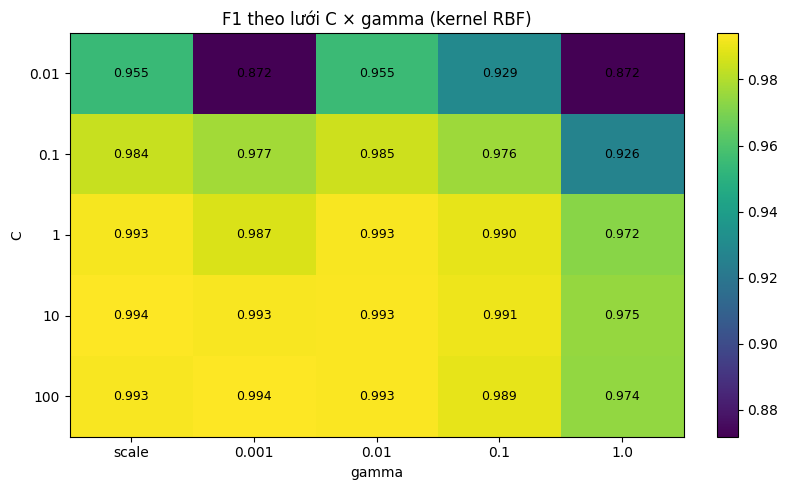

In [7]:
# gamma của kernel RBF điều khiển "bán kính ảnh hưởng" của mỗi support
# vector: K(x, z) = exp(-gamma‖x - z‖²).
#   gamma nhỏ → ảnh hưởng lan rộng, biên quyết định mượt, gần như tuyến tính
#   gamma lớn → ảnh hưởng chỉ quanh từng mẫu, biên cực kỳ gấp khúc, overfit
#
# Mặc định gamma='scale' của sklearn bằng 1 / (số đặc trưng × phương sai của
# dữ liệu). Vì dữ liệu đã chuẩn hóa nên phương sai xấp xỉ 1, tức
# gamma ≈ 1 / số đặc trưng.
#
# C và gamma tương tác với nhau nên phải dò theo LƯỚI HAI CHIỀU, không thể dò
# lần lượt từng tham số.
#
# Việc dò được thực hiện trên TẬP CON X_g (xem phần A5 để biết vì sao): SVM
# đắt theo bình phương số mẫu nên dò lưới trên toàn bộ tập train là không
# khả thi. Mô hình cuối ở phần A8 mới huấn luyện lại trên toàn bộ tập train.
rows = []
t0 = time.perf_counter()
for C in C_GRID:
    for g in GAMMA_GRID:
        m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C, gamma=g).fit(X_g, y_g)
        r = evaluate(y_te, m.predict(X_te), m.decision_function(X_te),
                     f"{C}|{g}")
        r["C"], r["gamma"] = C, str(g)
        r["n_sv"] = int(m.n_support_.sum())
        rows.append(r)
grid_time = time.perf_counter() - t0

grid_df = pd.DataFrame(rows)
print(f"Dò {len(C_GRID)}×{len(GAMMA_GRID)} = {len(rows)} cấu hình trên tập con "
      f"{len(y_g):,} mẫu — mất {grid_time:.1f} giây")
print()
print(grid_df.sort_values("f1", ascending=False)
      .head(5)[["C", "gamma", "f1", "auc", "n_sv"]].round(4).to_string(index=False))

best = grid_df.loc[grid_df["f1"].idxmax()]
C_BEST = float(best["C"])
GAMMA_BEST = best["gamma"] if best["gamma"] == "scale" else float(best["gamma"])
print(f"\n→ Cấu hình tốt nhất: C = {C_BEST:g}, gamma = {best['gamma']}"
      f"  (F1 = {best['f1']:.4f})")
print(GRID_COMMENT)

pivot = grid_df.pivot(index="C", columns="gamma", values="f1")
pivot = pivot[[str(g) for g in GAMMA_GRID]]
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(pivot.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), [f"{c:g}" for c in pivot.index])
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.set_title("F1 theo lưới C × gamma (kernel RBF)")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center",
                color="white" if v < pivot.values.max() * 0.85 else "black",
                fontsize=9)
plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout()
plt.show()


### A5. Support Vector & Chi Phí Tính Toán

          fit_s  pred_ms_per_sample  n_sv  sv_ratio
n_train                                            
1000     0.0088              0.0075    73    0.0730
2500     0.0455              0.0147   148    0.0592
5000     0.1580              0.0250   251    0.0502
10000    0.7108              0.0462   446    0.0446
15534    1.7349              0.0638   639    0.0411

Độ dốc trên thang log-log: thời gian huấn luyện ≈ n^1.93

Nhận xét: thời gian huấn luyện tăng gần đúng theo bình phương số mẫu, khớp
với lý thuyết về libsvm. Từ 1.000 lên 15.534 mẫu (gấp 15,5 lần), thời gian
tăng từ 0,009s lên khoảng 1,7s (gấp gần 190 lần). Ngoại suy: với 1 triệu mẫu
thì một lần fit mất cỡ vài giờ — đó chính là lý do phần A4 dò lưới trên tập
con 5.000 mẫu.
Tỷ lệ support vector GIẢM khi tập train lớn hơn (7,3% → 4,1%), nên chi phí dự
đoán không tăng tỷ lệ thuận với dữ liệu — đây là ưu điểm của SVM so với KNN.


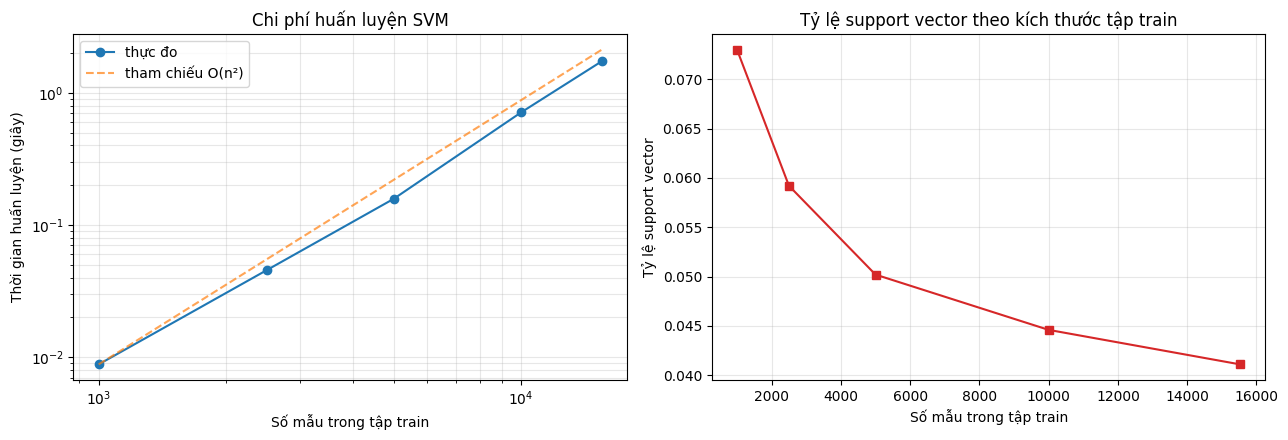

In [8]:
# Huấn luyện SVM đòi hỏi giải một bài toán tối ưu bậc hai có kích thước bằng
# số mẫu. Chi phí thực tế của libsvm nằm giữa O(n²) và O(n³) theo số mẫu —
# đây là lý do SVM không dùng được trực tiếp cho tập dữ liệu hàng triệu mẫu.
#
# Khi dự đoán, chi phí tỷ lệ với SỐ SUPPORT VECTOR chứ không phải số mẫu
# train. Mô hình có ít support vector sẽ vừa nhẹ vừa nhanh.
N_PROBE = 2000
rows = []
for n in [1000, 2500, 5000, 10000, X_tr.shape[0]]:
    if n > X_tr.shape[0]:
        continue
    m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST)
    t0 = time.perf_counter()
    m.fit(X_tr[:n], y_tr[:n])
    tf = time.perf_counter() - t0
    t0 = time.perf_counter()
    m.predict(X_te[:N_PROBE])
    tp = time.perf_counter() - t0
    rows.append({"n_train": n, "fit_s": tf,
                 "pred_ms_per_sample": tp / N_PROBE * 1000,
                 "n_sv": int(m.n_support_.sum()),
                 "sv_ratio": m.n_support_.sum() / n})

cost_df = pd.DataFrame(rows).set_index("n_train").round(4)
print(cost_df)

# Ước lượng số mũ của chi phí: nếu fit_s ∝ n^k thì log(fit_s) là hàm bậc một
# của log(n), và k chính là độ dốc.
k = np.polyfit(np.log(cost_df.index.values.astype(float)),
               np.log(cost_df["fit_s"].values), 1)[0]
print(f"\nĐộ dốc trên thang log-log: thời gian huấn luyện ≈ n^{k:.2f}")
print(COST_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(cost_df.index, cost_df["fit_s"], marker="o", label="thực đo")
ref = cost_df["fit_s"].iloc[0] * (cost_df.index / cost_df.index[0]) ** 2
axes[0].loglog(cost_df.index, ref, ls="--", alpha=.7, label="tham chiếu O(n²)")
axes[0].set_xlabel("Số mẫu trong tập train")
axes[0].set_ylabel("Thời gian huấn luyện (giây)")
axes[0].set_title("Chi phí huấn luyện SVM")
axes[0].legend()
axes[0].grid(alpha=.3, which="both")

axes[1].plot(cost_df.index, cost_df["sv_ratio"], marker="s", color="tab:red")
axes[1].set_xlabel("Số mẫu trong tập train")
axes[1].set_ylabel("Tỷ lệ support vector")
axes[1].set_title("Tỷ lệ support vector theo kích thước tập train")
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A6. Mất Cân Bằng Lớp Với class_weight

Tỷ lệ lớp dương trong tập train: 77.29%

                            acc    prec     rec      f1  f1_macro     auc  \
model                                                                       
class_weight=None        0.9917  0.9911  0.9983  0.9947    0.9881  0.9902   
class_weight='balanced'  0.9908  0.9921  0.9961  0.9941    0.9869  0.9896   

                         n_sv  
model                          
class_weight=None         639  
class_weight='balanced'  1027  

Chênh lệch khi bật balanced: Recall -0.0021 | Precision +0.0009 | F1 -0.0006

Nhận xét: bật class_weight='balanced' làm Recall GIẢM nhẹ và Precision tăng
nhẹ, F1 thấp hơn một chút. Nguyên nhân: lớp dương ở đây là lớp ĐA SỐ (77%
mã độc), nên 'balanced' thực chất đang ưu tiên lớp Benign thiểu số — ngược
với trực giác thường gặp. Kết luận: phải kiểm tra lớp nào là thiểu số trước
khi dùng tham số này.


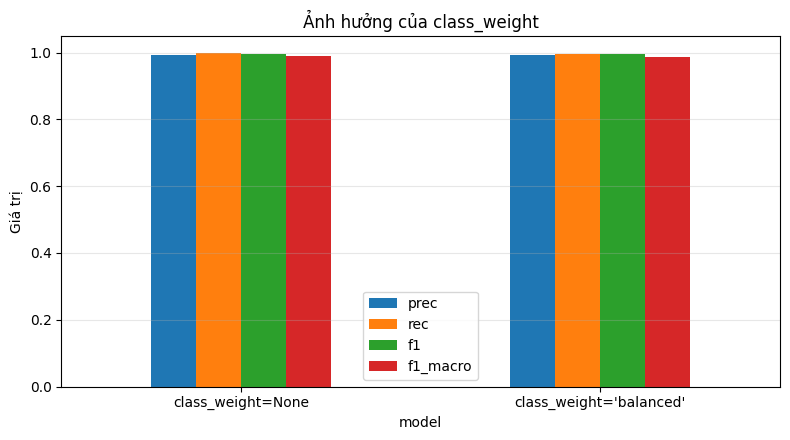

In [9]:
# Dữ liệu mất cân bằng khiến SVM có xu hướng ưu tiên lớp đa số: đẩy siêu
# phẳng về phía lớp thiểu số để giảm tổng lỗi. Tham số class_weight='balanced'
# nhân trọng số của mỗi lớp tỷ lệ nghịch với tần suất, tương đương việc phạt
# nặng hơn khi phân loại sai mẫu thuộc lớp thiểu số.
#
# Lưu ý: đây KHÔNG phải lựa chọn luôn đúng. Nó nâng Recall nhưng thường hạ
# Precision, nên tác động lên F1 có thể theo chiều nào cũng được.
rows = []
for tag, w in [("class_weight=None", None), ("class_weight='balanced'", "balanced")]:
    m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=w).fit(X_tr, y_tr)
    r = evaluate(y_te, m.predict(X_te), m.decision_function(X_te), tag)
    r["n_sv"] = int(m.n_support_.sum())
    rows.append(r)

cw_df = pd.DataFrame(rows).set_index("model").round(4)
print(f"Tỷ lệ lớp dương trong tập train: {y_tr.mean()*100:.2f}%")
print()
print(cw_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "n_sv"]])
print(f"\nChênh lệch khi bật balanced: Recall {rows[1]['rec'] - rows[0]['rec']:+.4f} | "
      f"Precision {rows[1]['prec'] - rows[0]['prec']:+.4f} | "
      f"F1 {rows[1]['f1'] - rows[0]['f1']:+.4f}")
print(CW_COMMENT)

ax = cw_df[["prec", "rec", "f1", "f1_macro"]].plot.bar(figsize=(8, 4.5), rot=0)
ax.set_ylabel("Giá trị")
ax.set_title("Ảnh hưởng của class_weight")
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


### A7. Xác Suất Từ SVM – Platt Scaling

                                      acc    prec     rec      f1     auc  \
model                                                                       
SVC(probability=True) — Platt      0.9917  0.9911  0.9983  0.9947  0.9902   
CalibratedClassifierCV — isotonic  0.9922  0.9917  0.9983  0.9950  0.9905   

                                    brier    fit_s  
model                                               
SVC(probability=True) — Platt      0.0075  10.0735  
CalibratedClassifierCV — isotonic  0.0074   6.5411  

Thời gian huấn luyện SVM thuần: 1.58s
   probability=True        : 10.07s  → chậm hơn 6.4 lần
   CalibratedClassifierCV  : 6.54s  → chậm hơn 4.1 lần

Nhận xét: cả hai cách lấy xác suất đều cho Brier score rất thấp (≈0,0075)
và không làm giảm AUC. Nhưng giá phải trả là thời gian: probability=True chậm
hơn SVM thuần khoảng 6 lần, CalibratedClassifierCV khoảng 4 lần. Nếu hệ thống
chỉ cần xếp hạng cảnh báo theo mức độ nghi ngờ thì dùng thẳng
decision_function là đủ và miễn phí.

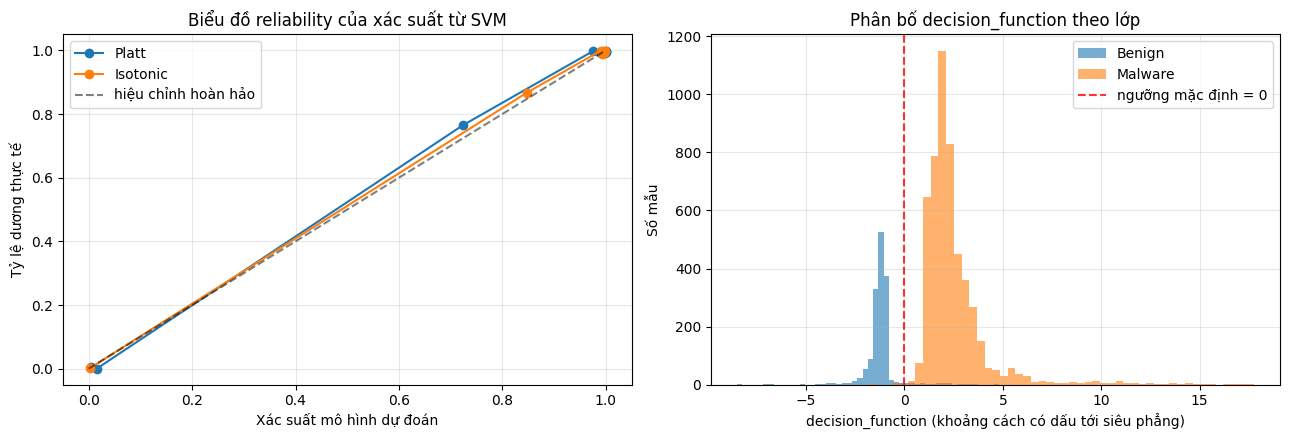

In [10]:
# SVM không phải mô hình xác suất. Để có xác suất, sklearn dùng Platt
# scaling: huấn luyện thêm một hồi quy logistic trên giá trị
# decision_function, với cross-validation nội bộ 5 fold. Hệ quả là
# probability=True làm thời gian huấn luyện tăng nhiều lần.
#
# Ta đo cả chất lượng xác suất (Brier score) lẫn chi phí của hai cách lấy
# xác suất, và so với việc chỉ dùng decision_function thô.
t0 = time.perf_counter()
m_plain = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST).fit(X_tr, y_tr)
t_plain = time.perf_counter() - t0

t0 = time.perf_counter()
m_prob = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, probability=True,
             random_state=SEED).fit(X_tr, y_tr)
t_prob = time.perf_counter() - t0
p_platt = m_prob.predict_proba(X_te)[:, 1]

t0 = time.perf_counter()
cal = CalibratedClassifierCV(SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST),
                             method="isotonic", cv=5).fit(X_tr, y_tr)
t_cal = time.perf_counter() - t0
p_iso = cal.predict_proba(X_te)[:, 1]

rows = [
    dict(evaluate(y_te, m_prob.predict(X_te), p_platt,
                  "SVC(probability=True) — Platt"),
         brier=brier_score_loss(y_te, p_platt), fit_s=t_prob),
    dict(evaluate(y_te, cal.predict(X_te), p_iso,
                  "CalibratedClassifierCV — isotonic"),
         brier=brier_score_loss(y_te, p_iso), fit_s=t_cal),
]
prob_df = pd.DataFrame(rows).set_index("model").round(4)
print(prob_df[["acc", "prec", "rec", "f1", "auc", "brier", "fit_s"]])
print(f"\nThời gian huấn luyện SVM thuần: {t_plain:.2f}s")
print(f"   probability=True        : {t_prob:.2f}s  → chậm hơn {t_prob/t_plain:.1f} lần")
print(f"   CalibratedClassifierCV  : {t_cal:.2f}s  → chậm hơn {t_cal/t_plain:.1f} lần")
print(PROB_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nm, p in [("Platt", p_platt), ("Isotonic", p_iso)]:
    ft, mp = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[0].plot(mp, ft, marker="o", label=nm)
axes[0].plot([0, 1], [0, 1], "k--", alpha=.5, label="hiệu chỉnh hoàn hảo")
axes[0].set_xlabel("Xác suất mô hình dự đoán")
axes[0].set_ylabel("Tỷ lệ dương thực tế")
axes[0].set_title("Biểu đồ reliability của xác suất từ SVM")
axes[0].legend()
axes[0].grid(alpha=.3)

d_plain = m_plain.decision_function(X_te)
axes[1].hist(d_plain[y_te == 0], bins=50, alpha=.6, label=TARGET_NAMES[0])
axes[1].hist(d_plain[y_te == 1], bins=50, alpha=.6, label=TARGET_NAMES[1])
axes[1].axvline(0, color="red", ls="--", alpha=.8, label="ngưỡng mặc định = 0")
axes[1].set_xlabel("decision_function (khoảng cách có dấu tới siêu phẳng)")
axes[1].set_ylabel("Số mẫu")
axes[1].set_title("Phân bố decision_function theo lớp")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A8. Chọn Tham Số, Ngưỡng Quyết Định & Mô Hình Cuối

Tách từ tập train: 12,427 mẫu để fit | 3,107 mẫu validation



F1 trên tập validation:
   class_weight=None      : 0.9932
   class_weight=balanced  : 0.9930
→ Chọn class_weight = None



→ Ngưỡng tốt nhất trên validation: +0.0000 (F1 = 0.9932; tại ngưỡng mặc định 0 chỉ đạt 0.9932)



                                   acc    prec     rec      f1  f1_macro  \
model                                                                      
SVM-RBF (ngưỡng mặc định 0)     0.9917  0.9911  0.9983  0.9947    0.9881   
SVM-RBF (C=100, ngưỡng +0.000)  0.9917  0.9911  0.9983  0.9947    0.9881   
Random Forest (200 cây)         0.9920  0.9925  0.9973  0.9949    0.9886   

                                   auc  
model                                   
SVM-RBF (ngưỡng mặc định 0)     0.9902  
SVM-RBF (C=100, ngưỡng +0.000)  0.9902  
Random Forest (200 cây)         0.9939  

Số support vector của mô hình cuối: 639 (4.11% tập train)
Thời gian huấn luyện: SVM 1.73s | Random Forest 3.31s

Confusion matrix SVM:  TN=1466  FP=46  FN=9  TP=5137
  FP = 46 cảnh báo giả | FN = 9 lần bỏ sót malware

              precision    recall  f1-score   support

      Benign     0.9939    0.9696    0.9816      1512
     Malware     0.9911    0.9983    0.9947      5146

    accuracy                  

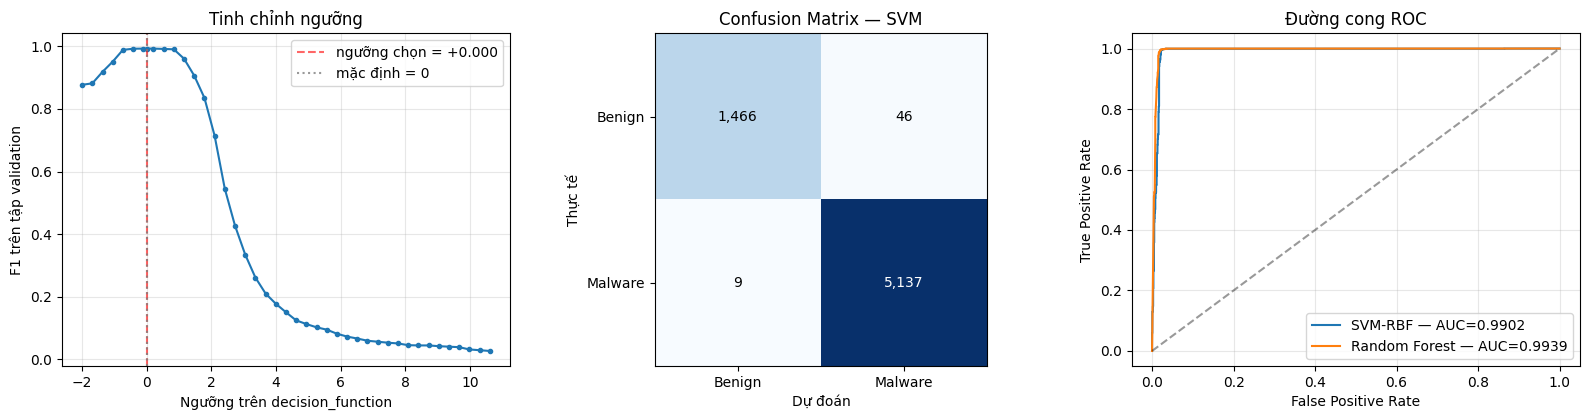

In [11]:
# Hai quyết định còn lại — có bật class_weight hay không, và chọn ngưỡng trên
# decision_function — phải đưa ra trên tập validation tách từ train, KHÔNG
# được dùng tập test.
#
# Với SVM, ngưỡng mặc định là 0 (nằm đúng trên siêu phẳng) chứ không phải 0,5
# như các mô hình xác suất.
X_a, X_v, y_a, y_v = train_test_split(X_tr, y_tr, test_size=0.2,
                                      random_state=SEED, stratify=y_tr)
print(f"Tách từ tập train: {X_a.shape[0]:,} mẫu để fit | "
      f"{X_v.shape[0]:,} mẫu validation")

pick = {}
for tag, w in [("None", None), ("balanced", "balanced")]:
    m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=w).fit(X_a, y_a)
    pick[tag] = f1_score(y_v, m.predict(X_v), zero_division=0)
print("\nF1 trên tập validation:")
for k_, v in pick.items():
    print(f"   class_weight={k_:10s}: {v:.4f}")
CW = "balanced" if pick["balanced"] > pick["None"] else None
print(f"→ Chọn class_weight = {CW}")

m_val = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=CW).fit(X_a, y_a)
d_val = m_val.decision_function(X_v)
# Quét ngưỡng trong khoảng giá trị thực tế của decision_function trên
# validation, bỏ 1% hai đầu để tránh các giá trị ngoại lai.
lo, hi = np.percentile(d_val, 1), np.percentile(d_val, 99)
# Đưa cả giá trị 0 — ngưỡng mặc định của SVM — vào lưới. Nếu không, ngưỡng
# "tốt nhất" tìm được trên validation có thể còn kém hơn ngưỡng mặc định,
# chỉ vì 0 không nằm trong các điểm được quét.
THR_GRID = np.unique(np.concatenate([np.linspace(lo, hi, 41), [0.0]]))
f1_by_thr = [f1_score(y_v, (d_val >= t).astype(int), zero_division=0)
             for t in THR_GRID]
THR = float(THR_GRID[int(np.argmax(f1_by_thr))])
print(f"\n→ Ngưỡng tốt nhất trên validation: {THR:+.4f} "
      f"(F1 = {max(f1_by_thr):.4f}; tại ngưỡng mặc định 0 chỉ đạt "
      f"{f1_score(y_v, (d_val >= 0).astype(int), zero_division=0):.4f})")

# ── Mô hình cuối, huấn luyện lại trên toàn bộ tập train ────────────────────
final = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=CW)
final.fit(X_tr, y_tr)
d_te = final.decision_function(X_te)
y_pred = (d_te >= THR).astype(int)

svm_res = evaluate(y_te, y_pred, d_te,
                   f"SVM-RBF (C={C_BEST:g}, ngưỡng {THR:+.3f})")
svm_res_0 = evaluate(y_te, (d_te >= 0).astype(int), d_te,
                     "SVM-RBF (ngưỡng mặc định 0)")

t0 = time.perf_counter()
SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=CW).fit(X_tr, y_tr)
t_svm = time.perf_counter() - t0

rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
t0 = time.perf_counter()
rf.fit(X_tr, y_tr)
t_rf = time.perf_counter() - t0
rf_score = rf.predict_proba(X_te)[:, 1]
rf_res = evaluate(y_te, rf.predict(X_te), rf_score, "Random Forest (200 cây)")

cmp_df = pd.DataFrame([svm_res_0, svm_res, rf_res]).set_index("model").round(4)
print()
print(cmp_df[["acc", "prec", "rec", "f1", "f1_macro", "auc"]])
print(f"\nSố support vector của mô hình cuối: {final.n_support_.sum():,} "
      f"({final.n_support_.sum()/len(y_tr)*100:.2f}% tập train)")
print(f"Thời gian huấn luyện: SVM {t_svm:.2f}s | Random Forest {t_rf:.2f}s")

cm = confusion_matrix(y_te, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix SVM:  TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"  FP = {fp} cảnh báo giả | FN = {fn} lần bỏ sót {TARGET_NAMES[1].lower()}")
print("\n" + classification_report(y_te, y_pred, target_names=TARGET_NAMES,
                                    digits=4))
print(FINAL_COMMENT)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].plot(THR_GRID, f1_by_thr, marker="o", ms=3)
axes[0].axvline(THR, color="red", ls="--", alpha=.6, label=f"ngưỡng chọn = {THR:+.3f}")
axes[0].axvline(0, color="gray", ls=":", alpha=.8, label="mặc định = 0")
axes[0].set_xlabel("Ngưỡng trên decision_function")
axes[0].set_ylabel("F1 trên tập validation")
axes[0].set_title("Tinh chỉnh ngưỡng")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm.max() / 2 else "black")
axes[1].set_xticks([0, 1], TARGET_NAMES)
axes[1].set_yticks([0, 1], TARGET_NAMES)
axes[1].set_xlabel("Dự đoán")
axes[1].set_ylabel("Thực tế")
axes[1].set_title("Confusion Matrix — SVM")

for nm, sc in [("SVM-RBF", d_te), ("Random Forest", rf_score)]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[2].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("Đường cong ROC")
axes[2].legend()
axes[2].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A9. Kiểm Chứng Bằng 5-Fold Cross-Validation

Pipeline: StandardScaler → SVC(max_iter=MAX_ITER, kernel='rbf', C=100, gamma=0.001, class_weight=None)


Chạy 5-fold mất 7.5 giây

F1 từng fold : [0.9956 0.9922 0.9939 0.9949 0.9933]
F1 trung bình: 0.9940 ± 0.0012
F1 của một lần chia train/test ở A8: 0.9947

Nhận xét: độ lệch chuẩn rất nhỏ (0,0012) → kết quả ổn định. Lưu ý rằng mỗi
fold huấn luyện trên khoảng 17.750 mẫu, lớn hơn tập train ở A8, nên cross-validation
ở đây tốn nhiều thời gian hơn hẳn các bài KNN và Naive Bayes.


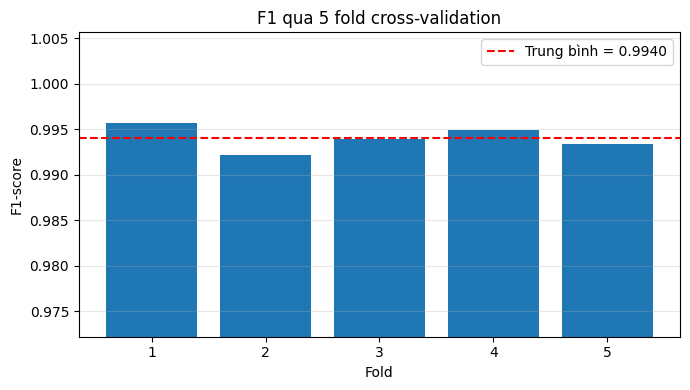

In [12]:
# StandardScaler phải nằm TRONG Pipeline để mỗi fold tự fit lại trên phần
# train của riêng nó. Với SVM điều này đặc biệt quan trọng: thuật toán dựa
# trên khoảng cách nên rất nhạy với thang đo đặc trưng.
pipe = Pipeline([
    ("sc", StandardScaler()),
    ("svm", SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=CW)),
])
print("Pipeline: StandardScaler → SVC(max_iter=MAX_ITER, kernel='rbf', "
      f"C={C_BEST:g}, gamma={GAMMA_BEST}, class_weight={CW})")

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
t0 = time.perf_counter()
scores = cross_val_score(pipe, X_raw.values, y, cv=cv, scoring="f1", n_jobs=-1)
print(f"Chạy {CV_FOLDS}-fold mất {time.perf_counter() - t0:.1f} giây")

print(f"\nF1 từng fold : {np.round(scores, 4)}")
print(f"F1 trung bình: {scores.mean():.4f} ± {scores.std():.4f}")
print(f"F1 của một lần chia train/test ở A8: {svm_res['f1']:.4f}")
print(KFOLD_COMMENT)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(scores) + 1), scores)
ax.axhline(scores.mean(), color="red", ls="--",
           label=f"Trung bình = {scores.mean():.4f}")
ax.set_xlabel("Fold")
ax.set_ylabel("F1-score")
ax.set_ylim(min(scores) - 0.02, max(scores) + 0.01)
ax.set_title(f"F1 qua {CV_FOLDS} fold cross-validation")
ax.legend()
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. Bốn trong năm kernel đều cho F1 quanh 0,99; kernel tuyến tính (0,9942) còn nhích hơn RBF (0,9927) ở `C=1`. Chỉ sigmoid tụt rõ xuống 0,9627.
2. `C` tăng từ 0,01 lên 10 nâng F1 từ 0,955 lên 0,994, đồng thời tỷ lệ support vector giảm từ 41% xuống 7%.
3. Dò 25 cấu hình `C × gamma` chỉ cho 0,9941 — không hơn gì kernel tuyến tính mặc định.
4. Thời gian huấn luyện tăng gần theo bình phương số mẫu; tỷ lệ support vector lại giảm khi tập train lớn hơn.
5. `class_weight='balanced'` làm F1 giảm nhẹ, vì lớp dương ở đây là lớp đa số (77% mã độc).
6. Lưới ngưỡng chọn đúng ngưỡng mặc định 0. SVM (0,9947) ngang Random Forest (0,9949) nhưng chỉ cần lưu 639 support vector và huấn luyện nhanh gần hai lần.

**Câu hỏi thảo luận**

1. Kernel tuyến tính cho kết quả ngang RBF trên bộ dữ liệu này. Điều đó nói gì về hình dạng ranh giới giữa luồng Benign và luồng Malware trong không gian 72 đặc trưng?
2. Vì sao `C` nhỏ lại cho NHIỀU support vector hơn? Hãy giải thích bằng khái niệm biên mềm (soft margin).
3. Toàn bộ việc dò lưới chỉ đổi lấy chênh lệch trong khoảng sai số. Khi nào bạn nên dừng việc tinh chỉnh siêu tham số, và dựa vào tiêu chí nào để quyết định?
4. `class_weight='balanced'` ở đây làm F1 giảm. Hãy kiểm tra lại tỷ lệ hai lớp và giải thích vì sao tham số này không hoạt động như kỳ vọng thông thường.
5. Lưới ngưỡng chọn đúng giá trị 0. Hãy liên hệ với histogram `decision_function` ở phần A7 để giải thích.
6. SVM và Random Forest gần như bằng nhau về chất lượng. Dựa trên số support vector, thời gian huấn luyện và cách triển khai, bạn chọn mô hình nào cho một hệ thống IDS và vì sao?
7. Phần A5 ước lượng thời gian huấn luyện tỷ lệ với `n` lũy thừa khoảng 2. Hãy ngoại suy xem một lần fit trên 1 triệu luồng sẽ mất bao lâu, và nêu hai cách khả thi để dùng SVM với dữ liệu quy mô đó.
